# 3.1 课堂数值实验：Euler 与经典 RK4

本实验与教材第 3.1 节配套，研究无量纲衰减方程 $y'=-y,\ y(0)=1$。在相同终止时刻下，比较向前 Euler、向后 Euler 与经典 RK4 的误差、收敛阶及计算成本；另以大步长检验稳定性。

**独立参考解：** $y(t)=e^{-t}$。向后 Euler 对当前线性方程可精确求解隐式更新式；一般非线性问题需要额外的方程求解过程。

In [1]:
import math
import sys
import platform
from pathlib import Path
import matplotlib
import matplotlib.pyplot as plt

OUTPUT_DIR = Path('images')
OUTPUT_DIR.mkdir(exist_ok=True)

def f(t, y):
    return -y

def exact(t):
    return math.exp(-t)

def forward_euler_step(t, y, h):
    return y + h*f(t, y)

def backward_euler_step(t, y, h):
    # Only for f(t,y) = -y. Solve (1+h)*y_next = y.
    return y/(1+h)

def rk4_step(t, y, h):
    k1 = f(t, y)
    k2 = f(t+h/2, y+h*k1/2)
    k3 = f(t+h/2, y+h*k2/2)
    k4 = f(t+h, y+h*k3)
    return y + h*(k1+2*k2+2*k3+k4)/6

METHODS = {
    'Forward Euler': forward_euler_step,
    'Backward Euler': backward_euler_step,
    'Classical RK4': rk4_step,
}

def solve(method, N, T=2.0, y0=1.0):
    if not isinstance(N, int) or isinstance(N, bool) or N < 1:
        raise ValueError('N must be a positive integer')
    if T <= 0:
        raise ValueError('T must be positive')
    h = T/N
    ts = [n*h for n in range(N+1)]
    ys = [float(y0)]
    for n in range(N):
        ys.append(method(ts[n], ys[-1], h))
    return ts, ys

print('Python:', sys.version.split()[0])
print('Matplotlib:', matplotlib.__version__)
print('Platform:', platform.system(), platform.machine())

Python: 3.10.13
Matplotlib: 3.9.0
Platform: Darwin arm64


## 一、单步计算与独立核对

步长 $h=0.5$ 时，向前 Euler 为 $0.5$，向后 Euler 为 $2/3$，RK4 为 $0.606770833333\ldots$。以下计算与解析递推关系独立比对。

In [2]:
for name, step in METHODS.items():
    print(f'{name:14s}: y(0.5) = {solve(step,1,T=0.5)[1][-1]:.12f}')
print(f'Exact solution: y(0.5) = {exact(0.5):.12f}')
assert abs(solve(forward_euler_step, 1, 0.5)[1][-1]-0.5) < 1e-13
assert abs(solve(backward_euler_step, 1, 0.5)[1][-1]-2/3) < 1e-13
assert abs(solve(rk4_step, 1, 0.5)[1][-1]-0.6067708333333333) < 1e-13
for N in (4, 8, 16, 32, 64):
    h=2/N
    r=1-h+h*h/2-h**3/6+h**4/24
    assert abs(solve(forward_euler_step,N)[1][-1]-(1-h)**N)<1e-12
    assert abs(solve(backward_euler_step,N)[1][-1]-(1+h)**(-N))<1e-12
    assert abs(solve(rk4_step,N)[1][-1]-r**N)<1e-12
print('One-step values and recurrence checks passed.')

Forward Euler : y(0.5) = 0.500000000000
Backward Euler: y(0.5) = 0.666666666667
Classical RK4 : y(0.5) = 0.606770833333
Exact solution: y(0.5) = 0.606530659713
One-step values and recurrence checks passed.


## 二、步长加密与误差比较

取 $T=2$，$N=4,8,16,32,64$，$h=2/N$。以终点绝对误差 $E_T(h)=|y_N-e^{-2}|$ 和 $p_{\rm obs}=\log_2\big(E_T(h)/E_T(h/2)\big)$ 衡量精度。

In [3]:
NS = [4, 8, 16, 32, 64]
RESULTS = {}
print('Exact reference y(2):', f'{exact(2):.12f}')
print(' N       h          FE(T)         BE(T)        RK4(T)')
for N in NS:
    values = {name: solve(step, N)[1][-1] for name, step in METHODS.items()}
    RESULTS[N] = {name: (value, abs(value-exact(2))) for name, value in values.items()}
    print(f"{N:2d}  {2/N:8.5f}  {values['Forward Euler']:.10f}  "
          f"{values['Backward Euler']:.10f}  {values['Classical RK4']:.10f}")
print('\n N       FE error        BE error        RK4 error')
for N in NS:
    errs = [RESULTS[N][name][1] for name in METHODS]
    print(f'{N:2d}   {errs[0]:.9e}   {errs[1]:.9e}   {errs[2]:.9e}')
print('\nN -> 2N    FE order   BE order   RK4 order')
for N in NS[:-1]:
    vals = [math.log2(RESULTS[N][name][1]/RESULTS[2*N][name][1]) for name in METHODS]
    print(f'{N:2d} -> {2*N:2d}    {vals[0]:8.4f}   {vals[1]:8.4f}    {vals[2]:8.4f}')

Exact reference y(2): 0.135335283237
 N       h          FE(T)         BE(T)        RK4(T)
 4   0.50000  0.0625000000  0.1975308642  0.1355497705
 8   0.25000  0.1001129150  0.1677721600  0.1353461420
16   0.12500  0.1180670870  0.1519006530  0.1353358945
32   0.06250  0.1267887864  0.1437056889  0.1353353195
64   0.03125  0.1310840325  0.1395424874  0.1353352854

 N       FE error        BE error        RK4 error
 4   7.283528324e-02   6.219558096e-02   2.144872706e-04
 8   3.522236820e-02   3.243687676e-02   1.085872052e-05
16   1.726819622e-02   1.656536976e-02   6.112327564e-07
32   8.546496860e-03   8.370405639e-03   3.625903053e-08
64   4.251250758e-03   4.207204198e-03   2.207871608e-09

N -> 2N    FE order   BE order   RK4 order
 4 ->  8      1.0481     0.9392      4.3040
 8 -> 16      1.0284     0.9695      4.1510
16 -> 32      1.0147     0.9848      4.0753
32 -> 64      1.0074     0.9924      4.0376


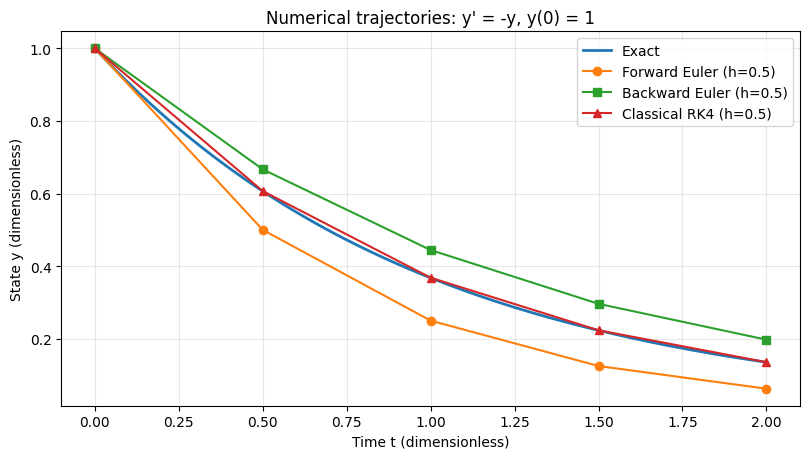

In [4]:
dense = [2*j/500 for j in range(501)]
plt.figure(figsize=(8.2, 4.7))
plt.plot(dense, [exact(t) for t in dense], label='Exact', linewidth=2)
for name, step, mark in zip(METHODS, METHODS.values(), ['o','s','^']):
    ts, ys = solve(step, 4)
    plt.plot(ts, ys, marker=mark, label=f'{name} (h=0.5)')
plt.title("Numerical trajectories: y' = -y, y(0) = 1")
plt.xlabel('Time t (dimensionless)')
plt.ylabel('State y (dimensionless)')
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.savefig(OUTPUT_DIR/'fig_3_1_1_trajectory.png', dpi=175)
plt.show()

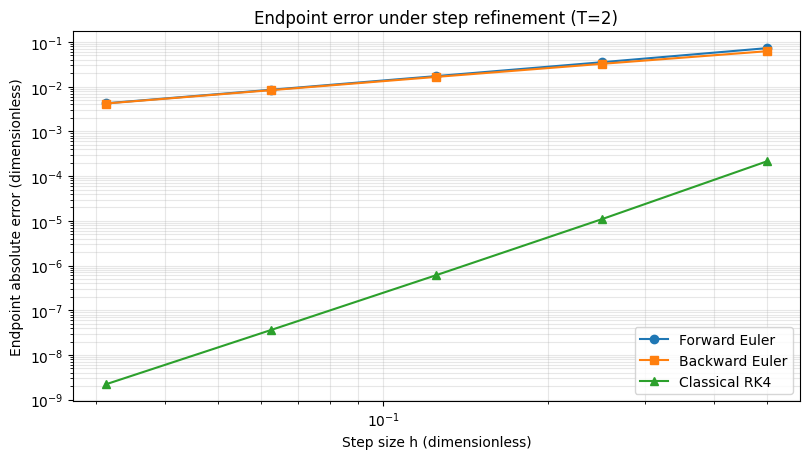

In [5]:
plt.figure(figsize=(8.2, 4.7))
for name, mark in zip(METHODS, ['o','s','^']):
    hs = [2/N for N in NS]
    errs = [RESULTS[N][name][1] for N in NS]
    plt.loglog(hs, errs, marker=mark, label=name)
plt.title('Endpoint error under step refinement (T=2)')
plt.xlabel('Step size h (dimensionless)')
plt.ylabel('Endpoint absolute error (dimensionless)')
plt.grid(alpha=0.3, which='both')
plt.legend()
plt.tight_layout()
plt.savefig(OUTPUT_DIR/'fig_3_1_2_convergence.png', dpi=175)
plt.show()

## 三、大步长稳定性实验

固定 $T=10$、$h=2.5$（共4步）。向前 Euler 的一步放大因子为 $-1.5$；向后 Euler 为 $2/7$；RK4 为 $0.6484375$。

Exact y(10): 4.539992976248e-05
Forward Euler  y(10)=5.062500000000  abs.err=5.062454600070
Backward Euler y(10)=0.006663890046  abs.err=0.006618490116
Classical RK4  y(10)=0.176796022803  abs.err=0.176750622873


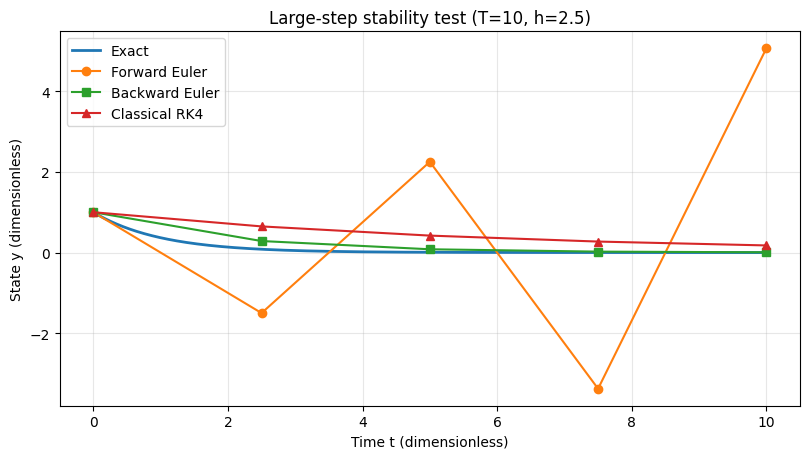

In [6]:
T_STAB, N_STAB = 10.0, 4
print('Exact y(10):', f'{exact(10):.12e}')
for name, step in METHODS.items():
    ts, ys = solve(step, N_STAB, T=T_STAB)
    print(f'{name:14s} y(10)={ys[-1]:.12f}  abs.err={abs(ys[-1]-exact(10)):.12f}')
dense = [10*j/700 for j in range(701)]
plt.figure(figsize=(8.2, 4.7))
plt.plot(dense, [exact(t) for t in dense], label='Exact', linewidth=2)
for name, step, mark in zip(METHODS, METHODS.values(), ['o','s','^']):
    ts, ys = solve(step, N_STAB, T=T_STAB)
    plt.plot(ts, ys, marker=mark, label=name)
plt.title('Large-step stability test (T=10, h=2.5)')
plt.xlabel('Time t (dimensionless)')
plt.ylabel('State y (dimensionless)')
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.savefig(OUTPUT_DIR/'fig_3_1_3_stability.png', dpi=175)
plt.show()

## 四、相同误差目标下的计算成本

规定终点绝对误差不超过 $10^{-4}$，只在 $N=4,8,16,\ldots$ 的二分加密候选网格中寻找首次达标值。向前 Euler 每步 1 次右端函数求值，RK4 每步 4 次。本例中的向后 Euler 用解析式求解线性隐式更新；其代价不能简单类比为一般非线性问题的固定右端函数求值次数。

In [7]:
TOL = 1e-4
for name, step in METHODS.items():
    for k in range(2, 18):
        N = 2**k
        E = abs(solve(step, N)[1][-1]-exact(2))
        if E <= TOL:
            if name == 'Backward Euler':
                cost = f'{N} scalar implicit equations (closed-form here)'
            else:
                cost = f'{N*(4 if name == "Classical RK4" else 1)} RHS evaluations'
            print(f'{name:14s}: N={N:5d}, h={2/N:.9f}, error={E:.10e}, cost={cost}')
            break
    else:
        raise AssertionError('The specified search range did not reach tolerance')
print('No random data or random seed is used.')

Forward Euler : N= 4096, h=0.000488281, error=6.6087059008e-05, cost=4096 RHS evaluations
Backward Euler: N= 4096, h=0.000488281, error=6.6076303527e-05, cost=4096 scalar implicit equations (closed-form here)
Classical RK4 : N=    8, h=0.250000000, error=1.0858720520e-05, cost=32 RHS evaluations
No random data or random seed is used.
